# Algorithmic Equity in Moderating Toxic Comments

**Research question:** Can automated toxicity moderation detect harmful language without disproportionately flagging comments that mention particular identities?

We built binary classifiers to label Civil Comments as **toxic (1)** or **non-toxic (0)**. We compared how well different models detect toxicity and whether they incorrectly flag non-toxic comments mentioning certain identities more often than other comments.

**Dataset:** Jigsaw Unintended Bias in Toxicity Classification (Civil Comments), downloaded from [Hugging Face](https://huggingface.co/datasets/shuttie/jigsaw-unintended-bias). We label a comment toxic when its `target` score is at least 0.5. We use identity annotation scores of at least 0.5 to identify comments mentioning each group; these annotations are for evaluation, not model inputs.

**Reproducibility:** The notebook downloads the dataset and runs in Google Colab with Python 3 and internet access. We use stratified random samples with `random_state=42`. We choose model settings using validation data and reserve the test set for final evaluation. The full dataset is not included in this repository. The first code cell installs needed libraries (`huggingface_hub`, `scikit-learn`, and `statsmodels`); we also use `pandas`, `numpy`, and `matplotlib`.


## 1. Dataset loading and exploratory analysis

We first looked at the class distribution, missing and duplicate comments, comment lengths, and the availability of identity annotations. The dataset is imbalanced, with far more non-toxic comments than toxic ones. We use the identity annotations only when measuring subgroup performance.


In [1]:
%pip install -q huggingface_hub scikit-learn statsmodels

from huggingface_hub import hf_hub_download
import pandas as pd

# Download directly from Hugging Face
path = hf_hub_download(
    repo_id="shuttie/jigsaw-unintended-bias",
    filename="data/train.csv.gz",
    repo_type="dataset"
)

# Load the dataset
df = pd.read_csv(path, compression="gzip")

print(df.shape)
df.head()

data/train.csv.gz: reconstructing file:   0%|          |  0.00B /  286MB            

data/train.csv.gz: downloading bytes:           |  0.00B            

(1804874, 45)


,id,target,comment_text,severe_toxicity,obscene,identity_attack,insult,threat,asian,atheist,...,article_id,rating,funny,wow,sad,likes,disagree,sexual_explicit,identity_annotator_count,toxicity_annotator_count
0,59848,0.000000,"This is so cool. It's like, 'would you want yo...",0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
1,59849,0.000000,Thank you!! This would make my life a lot less...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
2,59852,0.000000,This is such an urgent design problem; kudos t...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
3,59855,0.000000,Is this something I'll be able to install on m...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
4,59856,0.893617,haha you guys are a bunch of losers.,0.021277,0.0,0.021277,0.87234,0.0,0.0,0.0,...,2006,rejected,0,0,0,1,0,0.0,4,47


In [2]:
# Create binary toxicity labels
df["is_toxic"] = df["target"] >= 0.5

# Number of toxic and non-toxic comments
print(df["is_toxic"].value_counts())

# Percentage of each class
print(df["is_toxic"].value_counts(normalize=True) * 100)

is_toxic
False    1660540
True      144334
Name: count, dtype: int64
is_toxic
False    92.003098
True      7.996902
Name: proportion, dtype: float64


In [3]:
# Missing data
print("Missing comments:", df["comment_text"].isna().sum())
print("Missing toxicity scores:", df["target"].isna().sum())

# Duplicates
print("Duplicate comments:", df["comment_text"].duplicated().sum())

# Comment lengths
df["word_count"] = df["comment_text"].fillna("").str.count(r"\S+")

print("Average word count:", df["word_count"].mean())
print("Median word count:", df["word_count"].median())

Missing comments: 3
Missing toxicity scores: 0
Duplicate comments: 24051
Average word count: 51.27689467519616
Median word count: 35.0


In [4]:
identity_cols = [
    "male", "female", "transgender",
    "christian", "muslim", "jewish",
    "black", "white"
]

# Number of comments annotated as referencing each identity
identity_counts = (df[identity_cols] >= 0.5).sum()

print(identity_counts)

male           44484
female         53429
transgender     2499
christian      40423
muslim         21006
jewish          7651
black          14901
white          25082
dtype: int64


In [5]:
# How many comments have identity annotations?
print("Comments with identity annotations:",
      (df["identity_annotator_count"] > 0).sum())

# Count comments with at least one identity score >= 0.5
print("Comments referencing selected identities:",
      (df[identity_cols] >= 0.5).any(axis=1).sum())

Comments with identity annotations: 405130
Comments referencing selected identities: 155753


In [6]:
# Number of non-toxic comments referencing each identity
for col in identity_cols:
    count = ((df[col] >= 0.5) & (~df["is_toxic"])).sum()
    print(f"{col}: {count}")

male: 37799
female: 46118
transgender: 1967
christian: 36750
muslim: 16225
jewish: 6411
black: 10223
white: 18044


## 2. Preprocessing and data splits

We removed comments with missing text or toxicity scores and dropped duplicate comment texts before splitting the data. We then made stratified **70% training, 20% validation, and 10% test** splits so each split had approximately the same class distribution. We fit TF-IDF and scaling steps on training data rather than on validation or test data.


In [7]:
# Remove missing values for toxicity and text
copy = df.dropna(subset=["comment_text"]).copy()
copy = copy.dropna(subset = ["target"])
# Drop duplicate comments
copy = copy.drop_duplicates(subset = ["comment_text"])
copy = copy.reset_index(drop = True)

# Create new column for binary labels of toxicity
copy["is_toxic"] = (copy["target"] >= 0.5).astype(int)

# Missing data
print("Missing comments:", copy["comment_text"].isna().sum())
print("Missing toxicity scores:", copy["target"].isna().sum())

# Duplicates
print("Duplicate comments:", copy["comment_text"].duplicated().sum())

Missing comments: 0
Missing toxicity scores: 0
Duplicate comments: 0


In [8]:
# Train/validation/test split (70/20/10), stratified on the toxicity label.
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(copy, test_size=0.30, stratify=copy["is_toxic"], random_state=42) # stratify makes sure they all have same proportion of is_toxic

# temp is 30% of the data -> 2/3 validation (20%), 1/3 test (10%)
val_df, test_df = train_test_split(temp_df, test_size=1/3, stratify=temp_df["is_toxic"], random_state=42)

In [9]:
# Binary label flagging mention of identity groups in comments
# Same 0.5 threshold on the annotation scores as in the exploration above.
for d in (train_df, val_df, test_df):
    for col in identity_cols:
        d[f"{col}_mention"] = (d[col] >= 0.5)

# Non-toxic comments per identity in each split (the denominator of each group's false-positive rate)
counts = {
    name: {col: int((d[f"{col}_mention"] & (d["is_toxic"] == 0)).sum()) for col in identity_cols}
    for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]
}
pd.DataFrame(counts)

,train,val,test
male,26319,7438,3875
female,32185,9089,4613
transgender,1383,362,196
christian,25580,7394,3664
muslim,11210,3211,1659
jewish,4476,1287,603
black,7153,2002,1017
white,12478,3526,1888


## 3. Feature engineering and experimental samples

We compared two ways of representing comments. Our handcrafted features are **word count, uppercase-letter ratio, exclamation-mark count, question-mark count, and profanity count**. Our text-based models use **TF-IDF unigrams and bigrams** with up to 40,000 features (`min_df=3`). The vocabulary is learned from the training sample only.

For initial model comparisons, we used stratified samples of **100,000 training** and **30,000 validation** comments to keep experiments manageable. KNN used **20,000 training** comments because of its runtime. Its scores are useful as an exploratory baseline, but not a controlled comparison at the same training size. For subgroup fairness and matched-FPR analysis, we used the **full validation split**.


In [10]:
import pandas as pd

# Convert comment text into numerical features
def extract_features(comments):
    features = pd.DataFrame(index=comments.index)

    # Number of words
    features["word_count"] = comments.str.count(r"\S+")

    # Proportion of uppercase letters
    uppercase = comments.str.count(r"[A-Z]")
    letters = comments.str.count(r"[A-Za-z]")
    features["uppercase_ratio"] = uppercase / letters.clip(lower=1)

    # Punctuation counts
    features["exclamation_count"] = comments.str.count("!")
    features["question_count"] = comments.str.count(r"\?")

    # Count profanity using a small initial word list
    profanity_pattern = r"(?i)\b(?:fuck\w*|shit\w*|bitch\w*|asshole\w*|idiot\w*|stupid|damn)\b"
    features["profanity_count"] = comments.str.count(profanity_pattern)

    return features

# Test on a few example comments
examples = pd.Series([
    "Thank you for your help!",
    "YOU ARE SO STUPID!!!",
    "What do you think about this?"
])

extract_features(examples)


,word_count,uppercase_ratio,exclamation_count,question_count,profanity_count
0,5,0.052632,1,0,0
1,4,1.000000,3,0,1
2,6,0.043478,0,1,0


In [11]:
from sklearn.model_selection import train_test_split

# Use smaller, stratified samples for initial experiments
train_sample, _ = train_test_split(
    train_df,
    train_size=100000,
    stratify=train_df["is_toxic"],
    random_state=42
)

val_sample, _ = train_test_split(
    val_df,
    train_size=30000,
    stratify=val_df["is_toxic"],
    random_state=42
)

# Extract features
X_train = extract_features(train_sample["comment_text"])
X_val = extract_features(val_sample["comment_text"])

# Labels
y_train = train_sample["is_toxic"]
y_val = val_sample["is_toxic"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

display(X_train.head())

Training features: (100000, 5)
Validation features: (30000, 5)


,word_count,uppercase_ratio,exclamation_count,question_count,profanity_count
1011245,70,0.032895,0,0,0
33017,15,0.013514,0,0,0
168886,17,0.040000,0,0,0
1642220,157,0.027859,0,0,0
1368320,120,0.032659,0,0,0


## 4. Classifier training and hyperparameter tuning

We trained **seven classifier configurations**: Logistic Regression with handcrafted features, Logistic Regression with TF-IDF, Linear SVM with TF-IDF, Perceptron with TF-IDF, Multinomial Naive Bayes with TF-IDF, Gaussian Naive Bayes with handcrafted features, and KNN with handcrafted features. We also included a majority-class baseline.

For Linear SVM, we tested `C` values of **0.01, 0.1, 1, and 10** and selected the value with the highest toxic-class F1 on the 30,000-comment validation sample. The other models use the fixed settings shown in their code cells. The results in this section use each model's default classification decision rule; we compare a tuned Logistic Regression threshold in Section 5.


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Create model with feature standardization
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Train using training data
model.fit(X_train, y_train)

# Make predictions on validation data
y_pred = model.predict(X_val)

# Evaluate
print(classification_report(y_val, y_pred, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_val, y_pred))

# ROC-AUC uses predicted probabilities
y_scores = model.predict_proba(X_val)[:, 1]
print("ROC-AUC:", roc_auc_score(y_val, y_scores))


              precision    recall  f1-score   support

           0       0.93      1.00      0.96     27600
           1       0.81      0.18      0.30      2400

    accuracy                           0.93     30000
   macro avg       0.87      0.59      0.63     30000
weighted avg       0.92      0.93      0.91     30000

Confusion matrix:
[[27493   107]
 [ 1958   442]]
ROC-AUC: 0.6239618357487923


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# TF-IDF + Logistic Regression
tfidf_model = make_pipeline(
    TfidfVectorizer(
        max_features=40000,
        min_df=3,
        ngram_range=(1, 2)
    ),
    LogisticRegression(max_iter=1000)
)

# Train using the same training sample
tfidf_model.fit(
    train_sample["comment_text"],
    y_train
)

# Predict using the same validation sample
tfidf_pred = tfidf_model.predict(val_sample["comment_text"])
tfidf_scores = tfidf_model.predict_proba(
    val_sample["comment_text"]
)[:, 1]

# Evaluate
print(classification_report(y_val, tfidf_pred, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_val, tfidf_pred))
print("ROC-AUC:", roc_auc_score(y_val, tfidf_scores))


              precision    recall  f1-score   support

           0       0.94      1.00      0.97     27600
           1       0.88      0.22      0.35      2400

    accuracy                           0.94     30000
   macro avg       0.91      0.61      0.66     30000
weighted avg       0.93      0.94      0.92     30000

Confusion matrix:
[[27527    73]
 [ 1875   525]]
ROC-AUC: 0.9054458635265701


In [14]:
from sklearn.naive_bayes import MultinomialNB, GaussianNB

# Reuse TF-IDF representation for fair text-model comparisons
vectorizer = tfidf_model.named_steps["tfidfvectorizer"]

X_train_tfidf = vectorizer.transform(train_sample["comment_text"])
X_val_tfidf = vectorizer.transform(val_sample["comment_text"])

# Multinomial Naive Bayes with TF-IDF
mnb_model = MultinomialNB(alpha=1.0)
mnb_model.fit(X_train_tfidf, y_train)
mnb_pred = mnb_model.predict(X_val_tfidf)

print("Multinomial Naive Bayes:")
print(classification_report(y_val, mnb_pred, zero_division=0))

# Gaussian Naive Bayes with handcrafted numerical features
gnb_model = GaussianNB()
gnb_model.fit(X_train, y_train)
gnb_pred = gnb_model.predict(X_val)

print("Gaussian Naive Bayes:")
print(classification_report(y_val, gnb_pred, zero_division=0))

Multinomial Naive Bayes:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     27600
           1       0.95      0.02      0.05      2400

    accuracy                           0.92     30000
   macro avg       0.94      0.51      0.50     30000
weighted avg       0.92      0.92      0.89     30000

Gaussian Naive Bayes:
              precision    recall  f1-score   support

           0       0.93      0.98      0.96     27600
           1       0.49      0.21      0.29      2400

    accuracy                           0.92     30000
   macro avg       0.71      0.59      0.62     30000
weighted avg       0.90      0.92      0.90     30000



In [15]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
import numpy as np

# Use a smaller training sample for computational efficiency
knn_indices, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=20000,
    stratify=y_train,
    random_state=42
)

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15, weights="distance")
)

knn_model.fit(
    X_train.iloc[knn_indices],
    y_train.iloc[knn_indices]
)

knn_pred = knn_model.predict(X_val)

print("KNN:")
print(classification_report(y_val, knn_pred, zero_division=0))

KNN:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96     27600
           1       0.51      0.18      0.27      2400

    accuracy                           0.92     30000
   macro avg       0.72      0.58      0.61     30000
weighted avg       0.90      0.92      0.90     30000



### Linear SVM: choosing the regularization parameter

We compared four `C` values using validation binary F1. Smaller `C` means stronger regularization, while larger `C` puts more weight on fitting the training examples.


In [16]:
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score

c_values = [0.01, 0.1, 1, 10]
svm_tuning_results = []

best_f1 = -1
best_c = None
best_classifier = None

for c in c_values:
    classifier = LinearSVC(
        C=c,
        max_iter=3000,
        random_state=42
    )

    classifier.fit(X_train_tfidf, y_train)
    predictions = classifier.predict(X_val_tfidf)

    score = f1_score(y_val, predictions)

    svm_tuning_results.append({
        "C": c,
        "F1": score
    })

    if score > best_f1:
        best_f1 = score
        best_c = c
        best_classifier = classifier

display(pd.DataFrame(svm_tuning_results))

print("Best C:", best_c)
print("Best validation F1:", best_f1)

# Update SVM for the remaining notebook sections
svm_model = make_pipeline(vectorizer, best_classifier)

svm_scores = svm_model.decision_function(
    val_sample["comment_text"]
)

svm_pred = (svm_scores > 0).astype(int)

,C,F1
0,0.01,0.018985
1,0.10,0.343359
2,1.00,0.536942
3,10.00,0.492986


Best C: 1
Best validation F1: 0.5369418132611637


In [17]:
# Perceptron on TF-IDF (same features and training sample as the linear SVM)
from sklearn.linear_model import Perceptron

perceptron_model = Perceptron(random_state=42, max_iter=1000, tol=1e-3)
perceptron_model.fit(X_train_tfidf, y_train)

# Like the SVM, it gives a score (larger = more confidently toxic), not a probability
perceptron_scores = perceptron_model.decision_function(X_val_tfidf)
perceptron_pred = (perceptron_scores > 0).astype(int)

print("Perceptron:")
print(classification_report(y_val, perceptron_pred, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_val, perceptron_pred))
print("ROC-AUC:", roc_auc_score(y_val, perceptron_scores))


Perceptron:
              precision    recall  f1-score   support

           0       0.95      0.96      0.96     27600
           1       0.49      0.47      0.48      2400

    accuracy                           0.92     30000
   macro avg       0.72      0.72      0.72     30000
weighted avg       0.92      0.92      0.92     30000

Confusion matrix:
[[26425  1175]
 [ 1260  1140]]
ROC-AUC: 0.8451491998792271


### Majority-class baseline

Most comments are non-toxic, so predicting **non-toxic for every comment** gives relatively high accuracy. But it misses every toxic comment, resulting in zero toxic-class recall and binary F1. We use this baseline to show why accuracy alone is not enough.


In [18]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, recall_score

# Predict every comment as non-toxic
baseline_pred = np.zeros(len(y_val), dtype=int)

print("Baseline accuracy:", accuracy_score(y_val, baseline_pred))
print("Baseline recall:", recall_score(y_val, baseline_pred))
print("Baseline F1:", f1_score(y_val, baseline_pred))


Baseline accuracy: 0.92
Baseline recall: 0.0
Baseline F1: 0.0


## 5. Threshold sensitivity and model comparison

Logistic Regression outputs a toxicity probability. We evaluated several probability cutoffs on our **30,000-comment validation sample** and selected the cutoff with the highest **binary F1 for the toxic class**. A lower cutoff generally detects more toxic comments but can also increase false positives.

We use **binary F1** as our main detection metric because toxic comments are the positive class. We also report **macro F1**, which gives equal weight to toxic and non-toxic class performance. The best validation F1 was used to choose a threshold; our final performance estimates come from the held-out test set.


,Threshold,Precision,Recall,F1,FPR
0,0.05,0.175231,0.932083,0.295002,0.381486
1,0.10,0.359797,0.766667,0.489752,0.118623
2,0.15,0.507834,0.621250,0.558846,0.052355
3,0.20,0.614940,0.531667,0.570279,0.028949
4,0.25,0.689501,0.448750,0.543665,0.017572
5,0.30,0.754656,0.388333,0.512792,0.010978
6,0.35,0.792510,0.326250,0.462220,0.007428
7,0.40,0.830713,0.286250,0.425782,0.005072
8,0.45,0.868383,0.252917,0.391739,0.003333
9,0.50,0.877926,0.218750,0.350233,0.002645



Best threshold by validation F1:
Threshold    0.200000
Precision    0.614940
Recall       0.531667
F1           0.570279
FPR          0.028949
Name: 3, dtype: float64


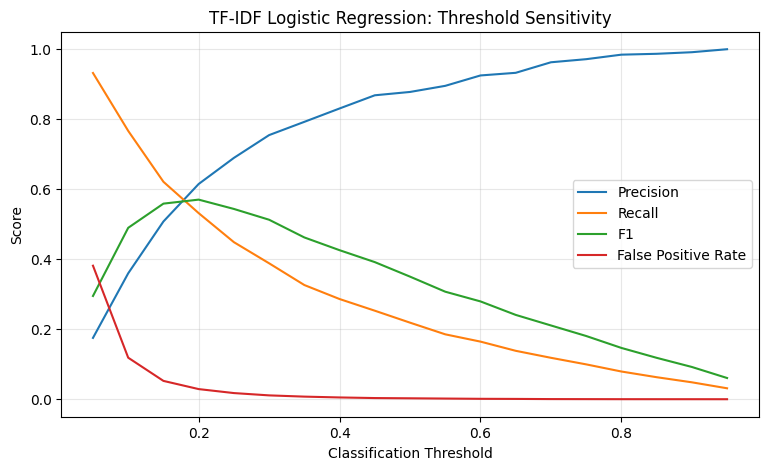

Selected Logistic Regression threshold: 0.20


In [19]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Test different classification thresholds
thresholds = np.arange(0.05, 1.0, 0.05)
results = []

for threshold in thresholds:
    predictions = (tfidf_scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "FPR": fp / (fp + tn)
    })

threshold_results = pd.DataFrame(results)

display(threshold_results)

# Find the threshold with the highest F1
best = threshold_results.loc[threshold_results["F1"].idxmax()]
print("\nBest threshold by validation F1:")
print(best)

# Visualize the trade-offs
plt.figure(figsize=(9, 5))

plt.plot(threshold_results["Threshold"], threshold_results["Precision"], label="Precision")
plt.plot(threshold_results["Threshold"], threshold_results["Recall"], label="Recall")
plt.plot(threshold_results["Threshold"], threshold_results["F1"], label="F1")
plt.plot(threshold_results["Threshold"], threshold_results["FPR"], label="False Positive Rate")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("TF-IDF Logistic Regression: Threshold Sensitivity")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Selected entirely from validation data (not the held-out test set).
best_lr_threshold = float(best["Threshold"])
print(f"Selected Logistic Regression threshold: {best_lr_threshold:.2f}")


### Validation results across models

This table compares the classifiers on the same validation sample. We show TF-IDF Logistic Regression at both the default **0.5** cutoff and the threshold selected for the highest validation F1. The Linear SVM appears once, using the `C` value chosen in the regularization search. KNN was trained on fewer examples, and the models use different feature representations, so these results describe the tested configurations rather than isolating the effect of model type alone.


In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# All predictions below concern the SAME 30,000-comment validation sample.
# The majority-class baseline and two LR thresholds are shown separately.
model_predictions = [
    ("Always non-toxic (baseline)", baseline_pred, "None", 0),
    ("Handcrafted Logistic Regression", y_pred, "Handcrafted", len(y_train)),
    ("TF-IDF Logistic Regression (0.5)", tfidf_pred, "TF-IDF", len(y_train)),
    (f"TF-IDF Logistic Regression (tuned {best_lr_threshold:.2f})",
     (tfidf_scores >= best_lr_threshold).astype(int), "TF-IDF", len(y_train)),
    (f"TF-IDF Linear SVM (C={best_c:g})", svm_pred, "TF-IDF", len(y_train)),
    ("TF-IDF Perceptron", perceptron_pred, "TF-IDF", len(y_train)),
    ("TF-IDF Multinomial Naive Bayes", mnb_pred, "TF-IDF", len(y_train)),
    ("Handcrafted Gaussian Naive Bayes", gnb_pred, "Handcrafted", len(y_train)),
    ("Handcrafted KNN (20k train)", knn_pred, "Handcrafted", len(knn_indices)),
]

comparison = pd.DataFrame([{
    "Model": name,
    "Features": features,
    "Train N": n,
    "Accuracy": accuracy_score(y_val, pred),
    "Precision": precision_score(y_val, pred, zero_division=0),
    "Recall": recall_score(y_val, pred, zero_division=0),
    "Binary F1": f1_score(y_val, pred, average="binary", zero_division=0),
    "Macro F1": f1_score(y_val, pred, average="macro", zero_division=0),
} for name, pred, features, n in model_predictions])

comparison = comparison.sort_values("Binary F1", ascending=False).reset_index(drop=True)
display(comparison.round(3))


,Model,Features,Train N,Accuracy,Precision,Recall,Binary F1,Macro F1
0,TF-IDF Logistic Regression (tuned 0.20),TF-IDF,100000,0.936,0.615,0.532,0.570,0.768
1,TF-IDF Linear SVM (C=1),TF-IDF,100000,0.943,0.766,0.413,0.537,0.753
2,TF-IDF Perceptron,TF-IDF,100000,0.919,0.492,0.475,0.484,0.720
3,TF-IDF Logistic Regression (0.5),TF-IDF,100000,0.935,0.878,0.219,0.350,0.658
4,Handcrafted Logistic Regression,Handcrafted,100000,0.931,0.805,0.184,0.300,0.632
5,Handcrafted Gaussian Naive Bayes,Handcrafted,100000,0.919,0.492,0.206,0.291,0.624
6,Handcrafted KNN (20k train),Handcrafted,20000,0.921,0.512,0.180,0.266,0.612
7,TF-IDF Multinomial Naive Bayes,TF-IDF,100000,0.922,0.951,0.024,0.047,0.503
8,Always non-toxic (baseline),None,0,0.920,0.000,0.000,0.000,0.479


## 6. False-positive rates by identity mention

Our fairness analysis focuses on **false positives**: non-toxic comments that a model incorrectly flags as toxic. For each identity-mention group, we calculate the percentage of actually non-toxic comments that are falsely flagged. We also show each group's sample size and a **95% Wilson confidence interval** to make uncertainty visible.

A group here means **comments annotated as mentioning an identity**, not comments written by people of that identity. A comment can belong to more than one group. We compare the Logistic Regression threshold selected in Section 5 with the default **0.5** cutoff using the full validation split.


In [21]:
# Shared helper that will be used in several subgroup fairness sections.
# For one model's predictions: FPR on non-toxic comments, overall and for each identity group,
# with 95% Wilson confidence intervals.
import numpy as np
import pandas as pd
from statsmodels.stats.proportion import proportion_confint

def subgroup_fpr(preds, labels, frame):
    """preds: boolean array of 'flagged toxic'; labels: 0/1 array; frame: dataframe with identity columns."""
    rows = []
    for group in ["overall"] + identity_cols:

        # group_mask filters comments by identity group
        if group == "overall":
            group_mask = np.ones(len(frame), dtype=bool)
        else:
            group_mask = (frame[group] >= 0.5).to_numpy()

        # Only consider actually non-toxic comments (the denominator of the FPR)
        mask = group_mask & (labels == 0)
        n = int(mask.sum())
        if n == 0:
            continue

        fp = int(preds[mask].sum())
        lower, upper = proportion_confint(fp, n, alpha=0.05, method="wilson")

        rows.append({
            "Group": group,
            "N": n,
            "False positives": fp,
            "FPR (%)": 100 * fp / n,
            "CI lower (%)": 100 * lower,
            "CI upper (%)": 100 * upper
        })
    return pd.DataFrame(rows)


In [22]:
import pandas as pd
import numpy as np

# Predict on the full validation set
scores = tfidf_model.predict_proba(val_df["comment_text"])[:, 1]
actual = val_df["is_toxic"].to_numpy()

# Use the same helper for both LR thresholds.
results = []

for threshold in [best_lr_threshold, 0.5]:
    predictions = scores >= threshold

    table = subgroup_fpr(predictions, actual, val_df)
    table = table.rename(columns={"N": "Non-toxic comments"})
    table.insert(0, "Threshold", threshold)
    results.append(table)

fairness_results = pd.concat(results, ignore_index=True)

display(fairness_results.round(2))

,Threshold,Group,Non-toxic comments,False positives,FPR (%),CI lower (%),CI upper (%)
0,0.2,overall,327674,9615,2.93,2.88,2.99
1,0.2,male,7438,775,10.42,9.75,11.13
2,0.2,female,9089,694,7.64,7.11,8.20
3,0.2,transgender,362,30,8.29,5.87,11.58
4,0.2,christian,7394,373,5.04,4.57,5.57
5,0.2,muslim,3211,565,17.60,16.32,18.95
6,0.2,jewish,1287,154,11.97,10.30,13.85
7,0.2,black,2002,562,28.07,26.15,30.08
8,0.2,white,3526,1055,29.92,28.43,31.45
9,0.5,overall,327674,791,0.24,0.23,0.26


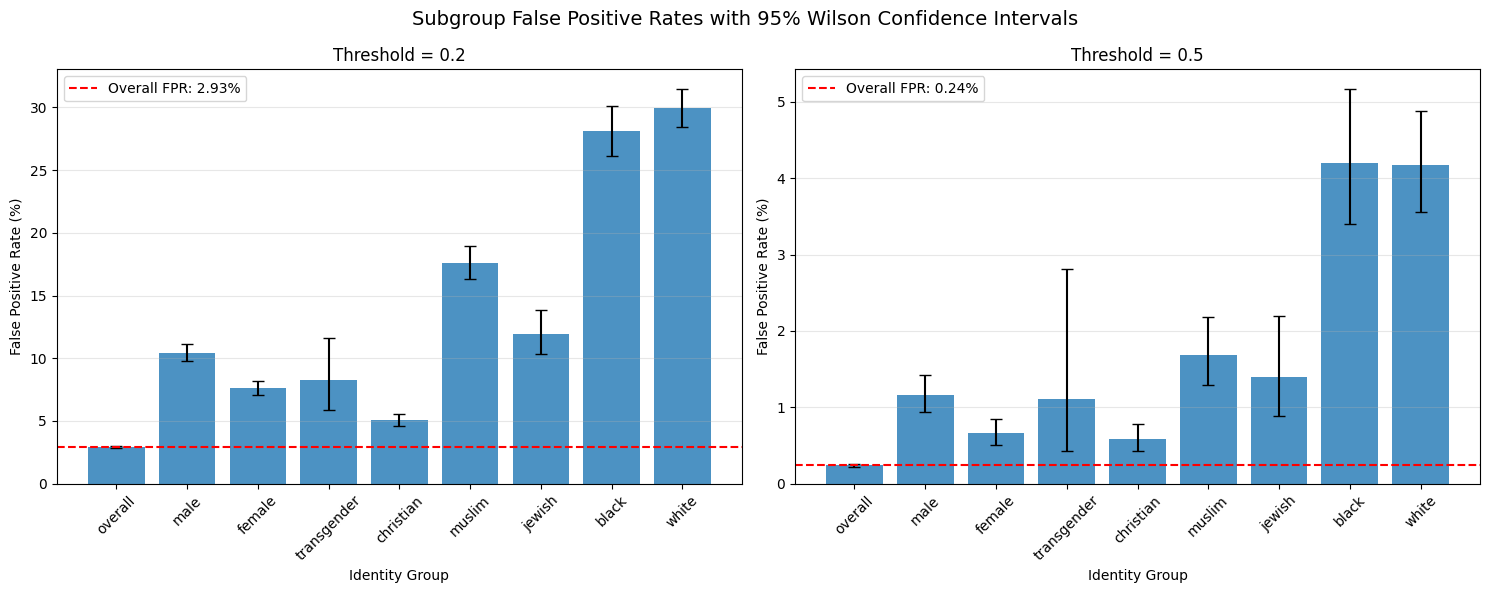

In [23]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, threshold in zip(axes, [best_lr_threshold, 0.5]):
    data = fairness_results[
        fairness_results["Threshold"] == threshold
    ].copy()

    # Keep original group order
    groups = data["Group"]
    fpr = data["FPR (%)"]

    # Calculate confidence interval error bars
    errors = [
        fpr - data["CI lower (%)"],
        data["CI upper (%)"] - fpr
    ]

    # Plot vertical bars
    ax.bar(groups, fpr, yerr=errors, capsize=4, alpha=0.8)

    # Overall FPR reference line
    overall_fpr = data.loc[
        data["Group"] == "overall", "FPR (%)"
    ].iloc[0]

    ax.axhline(
        overall_fpr,
        color="red",
        linestyle="--",
        label=f"Overall FPR: {overall_fpr:.2f}%"
    )

    ax.set_xlabel("Identity Group")
    ax.set_ylabel("False Positive Rate (%)")
    ax.set_title(f"Threshold = {threshold}")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Subgroup False Positive Rates with 95% Wilson Confidence Intervals",
    fontsize=14
)

plt.tight_layout()
plt.savefig("subgroup_fpr_confidence_intervals.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Comparing models at a similar overall false-positive rate

Logistic Regression, Linear SVM, Perceptron, and Multinomial Naive Bayes produce different kinds of scores, so comparing their raw scores directly would not be meaningful. Instead, we chose thresholds on the **full validation set** so the four models had approximately the same **overall false-positive rate** as Logistic Regression at its selected cutoff.

This gives us a more useful comparison of false-positive rates across identity-mention groups. We also compare toxic-class recall and F1, since a model can reduce false positives simply by flagging fewer comments overall. The results describe differences in model behavior; they do not establish why those differences occur.


In [24]:
# Compare four TF-IDF classifiers at approximately the same overall validation false-positive rate.
import numpy as np
import pandas as pd
from sklearn.metrics import recall_score, f1_score

actual = val_df["is_toxic"].to_numpy()

# Logistic Regression at the cutoff selected on the validation sample
lr_scores = tfidf_model.predict_proba(
    val_df["comment_text"]
)[:, 1]
lr_pred = lr_scores >= best_lr_threshold

# Target overall FPR: Logistic Regression at its validation-selected cutoff.
target_fpr = lr_pred[actual == 0].mean()

# Linear SVM: score the full validation set and match the target FPR
svm_scores_full = svm_model.decision_function(
    val_df["comment_text"]
)
svm_threshold = np.quantile(
    svm_scores_full[actual == 0],
    1 - target_fpr
)
svm_pred_full = svm_scores_full > svm_threshold
print("Linear SVM decision threshold:", svm_threshold)

val_tfidf_full = vectorizer.transform(val_df["comment_text"])

# Perceptron (TF-IDF)
perceptron_scores_full = perceptron_model.decision_function(val_tfidf_full)
perceptron_threshold = np.quantile(
    perceptron_scores_full[actual == 0],
    1 - target_fpr
)
perceptron_pred_full = perceptron_scores_full > perceptron_threshold
print("Perceptron decision threshold:", perceptron_threshold)

# Multinomial Naive Bayes (TF-IDF)
# Score = log-odds of toxic vs. non-toxic (larger = more confidently toxic)
mnb_log_probs = mnb_model.predict_log_proba(val_tfidf_full)
mnb_scores_full = mnb_log_probs[:, 1] - mnb_log_probs[:, 0]
mnb_threshold = np.quantile(
    mnb_scores_full[actual == 0],
    1 - target_fpr
)
mnb_pred_full = mnb_scores_full > mnb_threshold
print("Multinomial NB decision threshold:", mnb_threshold)

# subgroup_fpr is defined at the start of section 6

models_val = {
    "Logistic Regression": lr_pred,
    "Linear SVM": svm_pred_full,
    "Perceptron": perceptron_pred_full,
    "Multinomial NB": mnb_pred_full
}

results = []
for model_name, predictions in models_val.items():
    table = subgroup_fpr(predictions, actual, val_df)
    table.insert(0, "Model", model_name)
    results.append(table)

comparison_fairness = pd.concat(results, ignore_index=True)

display(
    comparison_fairness.pivot(
        index="Group",
        columns="Model",
        values="FPR (%)"
    )[list(models_val)].round(2)
)

for name, predictions in models_val.items():
    print(name)
    print("Recall:", round(recall_score(actual, predictions), 3))
    print("F1:", round(f1_score(actual, predictions), 3))


Linear SVM decision threshold: -0.2681958393048778
Perceptron decision threshold: 0.15597403246476968
Multinomial NB decision threshold: -2.0701541432175805


Model,Logistic Regression,Linear SVM,Perceptron,Multinomial NB
Group,,,,
black,28.07,20.03,13.74,8.94
christian,5.04,4.69,5.11,2.16
female,7.64,6.14,6.44,3.73
jewish,11.97,11.03,11.50,6.92
male,10.42,8.11,7.26,5.63
muslim,17.60,14.51,13.45,8.32
overall,2.93,2.93,2.93,2.93
transgender,8.29,7.46,6.91,4.70
white,29.92,18.94,11.15,14.83


Logistic Regression
Recall: 0.53
F1: 0.568
Linear SVM
Recall: 0.529
F1: 0.567
Perceptron
Recall: 0.421
F1: 0.478
Multinomial NB
Recall: 0.324
F1: 0.39


## 8. Understanding model predictions and errors

We looked at the words with the largest positive and negative coefficients in TF-IDF Logistic Regression. These weights show which terms push a prediction toward or away from the toxic class, **holding the other features fixed**. They do not show that a particular identity word caused an individual comment to be misclassified.

We also looked at examples of **false positives and false negatives from the validation set**, including false positives mentioning Black identity. These examples give context to the quantitative results, but we did not use them as a separately annotated dataset or to estimate the frequency of particular error patterns.


### Which words influence Logistic Regression predictions?

Positive coefficients increase the model's toxicity score; negative coefficients decrease it. We also checked where identity-related words appear among the learned coefficients.


In [25]:
# Logistic Regression weights for each word in the TF-IDF vocabulary
tfidf_vectorizer = tfidf_model.named_steps["tfidfvectorizer"]
lr_classifier = tfidf_model.named_steps["logisticregression"]

words = np.array(tfidf_vectorizer.get_feature_names_out())
weights = lr_classifier.coef_[0]

weight_table = pd.DataFrame({"Word": words, "Weight": weights})
weight_table["Rank (1 = most toxic-leaning)"] = weight_table["Weight"].rank(ascending=False).astype(int)

print("Top 20 words pushing toward TOXIC:")
display(weight_table.sort_values("Weight", ascending=False).head(20).round(2).reset_index(drop=True))

print("Top 20 words pushing toward NON-TOXIC:")
display(weight_table.sort_values("Weight").head(20).round(2).reset_index(drop=True))

# Where do identity-related words fall? (only words that are in the vocabulary appear)
identity_words = [
    "black", "white", "muslim", "muslims", "jewish", "christian", "christians",
    "gay", "transgender", "female", "male", "women", "men"
]
print(f"Identity-related words (out of {len(words)} words in total):")
display(
    weight_table[weight_table["Word"].isin(identity_words)]
    .sort_values("Weight", ascending=False)
    .round(2)
    .reset_index(drop=True)
)


Top 20 words pushing toward TOXIC:


,Word,Weight,Rank (1 = most toxic-leaning)
0,stupid,21.34,1
1,idiot,12.75,2
2,idiots,11.80,3
3,dumb,11.23,4
4,ignorant,11.19,5
5,stupidity,10.94,6
6,ridiculous,10.74,7
7,crap,10.72,8
8,pathetic,10.63,9
9,fool,9.30,10


Top 20 words pushing toward NON-TOXIC:


,Word,Weight,Rank (1 = most toxic-leaning)
0,years,-1.71,40000
1,this is,-1.70,39999
2,thank you,-1.68,39998
3,what is,-1.67,39997
4,correct,-1.66,39996
5,property,-1.60,39995
6,interesting,-1.57,39994
7,may,-1.54,39993
8,not,-1.52,39992
9,great,-1.51,39991


Identity-related words (out of 40000 words in total):


,Word,Weight,Rank (1 = most toxic-leaning)
0,gay,6.19,23
1,black,5.53,28
2,white,5.21,31
3,muslims,4.29,46
4,muslim,3.62,67
5,christians,2.69,106
6,women,1.85,158
7,men,1.30,310
8,christian,1.25,330
9,transgender,1.03,451


### Examples of validation-set errors

We sampled false positives and false negatives at the selected Logistic Regression threshold to see what kinds of comments the model misclassified.


In [26]:
# Error analysis for TF-IDF Logistic Regression
threshold = best_lr_threshold

analysis_df = val_df.copy()
analysis_df["predicted_score"] = scores
analysis_df["predicted_toxic"] = (scores >= threshold).astype(int)

# False positives: non-toxic comments predicted as toxic
false_positives = analysis_df[
    (analysis_df["is_toxic"] == 0) &
    (analysis_df["predicted_toxic"] == 1)
]

# False negatives: toxic comments predicted as non-toxic
false_negatives = analysis_df[
    (analysis_df["is_toxic"] == 1) &
    (analysis_df["predicted_toxic"] == 0)
]

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))

# Examine random examples of each error type
print("\nFalse positive examples:")
display(
    false_positives[
        ["comment_text", "target", "predicted_score"]
    ].sample(10, random_state=42)
)

print("\nFalse negative examples:")
display(
    false_negatives[
        ["comment_text", "target", "predicted_score"]
    ].sample(10, random_state=42)
)


False positives: 9615
False negatives: 13382

False positive examples:


,comment_text,target,predicted_score
824939,This is Justin Trudeau's dream. He gets to ope...,0.166667,0.258532
1361822,Another sore loser piling on. Smh,0.400000,0.710066
514003,All I know is that we Trump supporters gave Hi...,0.300000,0.221509
553512,Haters like you with no real points are the to...,0.472973,0.236097
1299060,"Cirincione, must've been a 'peace-nik' from th...",0.300000,0.283398
973432,"Blunt, I hope you are feeling better now that ...",0.000000,0.217293
1033797,Desperation ??? Looks like your bunch is the ...,0.400000,0.286644
1418585,I'm pretty sure Kim is quaking in his pants th...,0.314286,0.348709
670311,This is truly sickening and a huge black mark ...,0.000000,0.265566
198214,LOL - great troll. You have two bites already...,0.200000,0.340840



False negative examples:


,comment_text,target,predicted_score
430648,"From other news sources: ""US Senator John McCa...",0.5,0.097170
1171917,Let's give $10 million to a murdering terroris...,0.5,0.150016
1466727,The thing that staggers me is how pervasive th...,0.5,0.118562
825613,I guess we supposed to play by their rules. 1...,0.5,0.132414
124166,Looks that way. This is what it's come to; if...,0.5,0.064946
1109519,"LesterP, Hawaii is the state where Trump's fav...",0.7,0.166178
156794,True.....but I was hoping for a whole scale ex...,0.7,0.043911
135845,"""Slavery killed a lot more Africans than Nazis...",0.6,0.160731
839249,Good friend of mine had his residence and thou...,0.6,0.160471
1317430,What a brilliantly insightful comment! \n\nY...,0.5,0.061091


In [27]:

# Choose identity group to investigate
group = "black"

group_fp = false_positives[
    false_positives[group] >= 0.5
]

print(f"False positives mentioning {group}: {len(group_fp)}")

display(
    group_fp[
        ["comment_text", "target", "predicted_score"]
    ].sample(n=min(10, len(group_fp)), random_state=42)
)


False positives mentioning black: 562


,comment_text,target,predicted_score
1387796,"Bill, in these types of discussions, ""at least...",0.000000,0.384271
155201,There should be no assumption at all my friend...,0.000000,0.206066
1741069,MO imagines what she thinks must be true for a...,0.200000,0.553986
514620,"Really, these people must have no idea of who ...",0.000000,0.265356
1517022,yeah! watching news on the other african-ameri...,0.400000,0.224882
1260351,"""Of course the new black elite had to be accom...",0.166667,0.248716
201937,"""Until the media becomes honest and reports th...",0.400000,0.368602
978945,"He was a sometimes homeless guy, addicted to m...",0.200000,0.362449
257679,"Well Desa, when our nation no longer exist and...",0.000000,0.316607
892364,The number of bi-sexual males may be larger th...,0.100000,0.449716


## 9. Final evaluation on the held-out test set

After choosing model settings and thresholds on the validation data, we evaluated Logistic Regression, Linear SVM, Perceptron, and Multinomial Naive Bayes on the **held-out test set**. We report accuracy, precision, recall, binary F1, macro F1, ROC-AUC, and overall and subgroup false-positive rates.

The identity groups can overlap and vary in size, so we report confidence intervals alongside subgroup FPRs. The results show associations between identity mentions and model errors, not proof that identity mentions alone caused the errors.


In [28]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)
import pandas as pd
import numpy as np

# Final evaluation on the held-out test set
y_test = test_df["is_toxic"].to_numpy()
test_text = test_df["comment_text"]

# Use thresholds selected on validation data
lr_test_scores = tfidf_model.predict_proba(test_text)[:, 1]
svm_test_scores = svm_model.decision_function(test_text)

test_tfidf = vectorizer.transform(test_text)

perceptron_test_scores = perceptron_model.decision_function(test_tfidf)

mnb_test_log_probs = mnb_model.predict_log_proba(test_tfidf)
mnb_test_scores = mnb_test_log_probs[:, 1] - mnb_test_log_probs[:, 0]

models = {
    "Logistic Regression": (
        lr_test_scores, lr_test_scores >= best_lr_threshold
    ),
    "Linear SVM": (
        svm_test_scores, svm_test_scores > svm_threshold
    ),
    "Perceptron": (
        perceptron_test_scores, perceptron_test_scores > perceptron_threshold
    ),
    "Multinomial NB": (
        mnb_test_scores, mnb_test_scores > mnb_threshold
    )
}

metrics_results = []
fairness_results_test = []

for name, (model_scores, predictions) in models.items():

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    metrics_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "Binary F1": f1_score(y_test, predictions, average="binary", zero_division=0),
        "Macro F1": f1_score(y_test, predictions, average="macro", zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, model_scores),
        "FPR (%)": 100 * fp / (fp + tn)
    })

    # subgroup false-positive rates via the shared subgroup_fpr helper
    table = subgroup_fpr(predictions, y_test, test_df)
    table.insert(0, "Model", name)
    fairness_results_test.append(table)

# Display final results
test_metrics = pd.DataFrame(metrics_results)
test_fairness = pd.concat(fairness_results_test, ignore_index=True)

print("FINAL TEST PERFORMANCE")
display(test_metrics.round(3))

print("FINAL SUBGROUP FALSE-POSITIVE RATES")
display(
    test_fairness.pivot(
        index="Group",
        columns="Model",
        values="FPR (%)"
    ).round(2)
)

print("SUBGROUP CONFIDENCE INTERVALS")
display(test_fairness.round(2))


FINAL TEST PERFORMANCE


,Model,Accuracy,Precision,Recall,Binary F1,Macro F1,ROC-AUC,FPR (%)
0,Logistic Regression,0.935,0.607,0.530,0.566,0.765,0.907,2.979
1,Linear SVM,0.936,0.612,0.530,0.568,0.767,0.890,2.922
2,Perceptron,0.927,0.556,0.418,0.477,0.719,0.843,2.905
3,Multinomial NB,0.919,0.490,0.325,0.391,0.674,0.800,2.942


FINAL SUBGROUP FALSE-POSITIVE RATES


Model,Linear SVM,Logistic Regression,Multinomial NB,Perceptron
Group,,,,
black,23.60,32.06,12.00,14.75
christian,5.02,5.24,1.69,5.16
female,5.90,7.18,3.36,6.35
jewish,10.12,10.45,5.31,8.79
male,7.41,10.45,5.94,6.35
muslim,15.01,19.41,7.47,14.17
overall,2.92,2.98,2.94,2.91
transgender,8.16,6.12,4.59,11.22
white,19.17,29.34,16.10,10.75


SUBGROUP CONFIDENCE INTERVALS


,Model,Group,N,False positives,FPR (%),CI lower (%),CI upper (%)
0,Logistic Regression,overall,163838,4881,2.98,2.90,3.06
1,Logistic Regression,male,3875,405,10.45,9.53,11.45
2,Logistic Regression,female,4613,331,7.18,6.47,7.96
3,Logistic Regression,transgender,196,12,6.12,3.54,10.40
4,Logistic Regression,christian,3664,192,5.24,4.56,6.01
5,Logistic Regression,muslim,1659,322,19.41,17.58,21.38
6,Logistic Regression,jewish,603,63,10.45,8.25,13.14
7,Logistic Regression,black,1017,326,32.06,29.26,34.99
8,Logistic Regression,white,1888,554,29.34,27.33,31.44
9,Linear SVM,overall,163838,4787,2.92,2.84,3.00


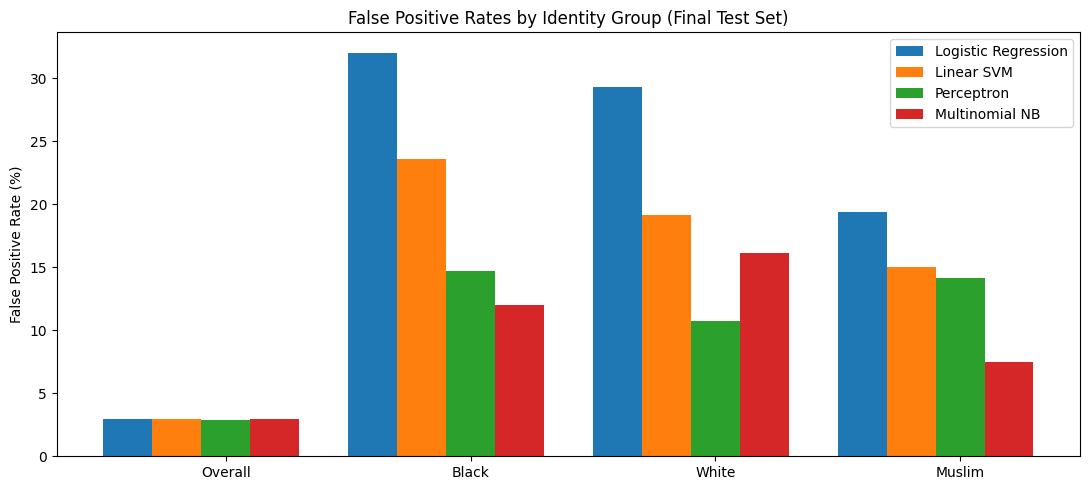

In [29]:
import matplotlib.pyplot as plt
import numpy as np

groups = ["overall", "black", "white", "muslim"]
model_names = ["Logistic Regression", "Linear SVM", "Perceptron", "Multinomial NB"]

data = test_fairness[
    test_fairness["Group"].isin(groups)
]

pivot = data.pivot(
    index="Group",
    columns="Model",
    values="FPR (%)"
).reindex(groups)

x = np.arange(len(groups))
width = 0.2

plt.figure(figsize=(11, 5))

# One bar per model for each group
for k, name in enumerate(model_names):
    plt.bar(x + (k - 2) * width, pivot[name], width, label=name)

plt.xticks(x, ["Overall", "Black", "White", "Muslim"])
plt.ylabel("False Positive Rate (%)")
plt.title("False Positive Rates by Identity Group (Final Test Set)")
plt.legend()
plt.tight_layout()

plt.savefig("final_fairness_comparison.png", dpi=300)
plt.show()


### Do the models make mistakes on the same comments?

We compared errors across the four models on the **same test examples**. To measure overlap, we used **Jaccard similarity**: the number of comments both models get wrong divided by the number that either model gets wrong.

We also separated errors shared by all models from errors made by only some models and looked at how often these comments mention identity groups. This helps us see whether mistakes are shared across classifiers or specific to particular models, although the overlap alone cannot explain the cause.


In [30]:
# Predictions on the same test set
lr_test_pred = (lr_test_scores >= best_lr_threshold).astype(int)
svm_test_pred = (svm_test_scores > svm_threshold).astype(int)

# Identify errors
lr_wrong = lr_test_pred != y_test
svm_wrong = svm_test_pred != y_test

both_wrong = lr_wrong & svm_wrong
lr_only = lr_wrong & ~svm_wrong
svm_only = svm_wrong & ~lr_wrong

print("Both wrong:", both_wrong.sum())
print("Only Logistic Regression wrong:", lr_only.sum())
print("Only SVM wrong:", svm_only.sum())

# Jaccard similarity of error sets
union = lr_wrong | svm_wrong
overlap = both_wrong.sum() / union.sum() if union.sum() else 1.0
print("Error overlap (Jaccard):", overlap)

# Inspect examples
error_df = test_df[["comment_text", "target", "is_toxic"]].copy()
error_df["LR prediction"] = lr_test_pred
error_df["SVM prediction"] = svm_test_pred

for name, mask in [
    ("Both wrong", both_wrong),
    ("Only Logistic Regression wrong", lr_only),
    ("Only SVM wrong", svm_only)
]:
    examples = error_df.loc[mask]
    print(name)
    display(examples.sample(
        n=min(5, len(examples)),
        random_state=42
    ))

Both wrong: 8735
Only Logistic Regression wrong: 2848
Only SVM wrong: 2748
Error overlap (Jaccard): 0.6095178284837066
Both wrong


,comment_text,target,is_toxic,LR prediction,SVM prediction
358898,This article is baloney!!!! Just a typical neg...,0.660377,1,0,0
554503,An act of terror is a crime of hatred. The unw...,0.600000,1,0,0
753409,Yo ho ho. The Art of the Deal. Ho Ho Ho.\nDona...,0.675676,1,0,0
322188,"You have selective reading skills, Skailak. H...",0.500000,1,0,0
1632192,Ungrateful Canadian!\nToo bad Donald saved the...,0.700000,1,0,0


Only Logistic Regression wrong


,comment_text,target,is_toxic,LR prediction,SVM prediction
1498179,Tom Moyane; an ignoramus wrapped in thick slic...,0.600000,1,0,1
85426,Great article and thanks for the insight. Tho...,0.500000,1,0,1
993338,I believe in Christ/God and His teaching. \nI...,0.400000,0,1,0
793555,"Really, Dromig10? So American racists voted ...",0.514286,1,0,1
837140,This picture reminds me of the movie Idiocracy...,0.700000,1,0,1


Only SVM wrong


,comment_text,target,is_toxic,LR prediction,SVM prediction
336073,Re-continued\n\nReaching as you need to do... ...,0.400000,0,0,1
369317,The response is technically correct and genera...,0.300000,0,0,1
1265181,Why doesn't the dumpster fire name a special c...,0.000000,0,0,1
1619852,Nothing worse than putting government in charg...,0.111111,0,0,1
1134677,LW1 - can i have that boys email? I'd like to...,0.500000,1,1,0


In [31]:
# Pairwise overlap of errors across all models on the test set
test_preds = {name: np.asarray(preds) for name, (scores_, preds) in models.items()}
wrong = {name: (p.astype(int) != y_test) for name, p in test_preds.items()}
names = list(wrong)

overlap = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        overlap.loc[a, b] = (wrong[a] & wrong[b]).sum() / (wrong[a] | wrong[b]).sum()

print("Error overlap between models (1 = same mistakes):")
display(overlap.round(3))

# How many models get each test comment wrong?
n_models_wrong = sum(w.astype(int) for w in wrong.values())
print("Test comments by number of models that got them wrong:")
display(pd.Series(n_models_wrong).value_counts().sort_index().rename_axis("Models wrong").to_frame("Comments"))


Error overlap between models (1 = same mistakes):


,Logistic Regression,Linear SVM,Perceptron,Multinomial NB
Logistic Regression,1.000,0.610,0.475,0.419
Linear SVM,0.610,1.000,0.630,0.408
Perceptron,0.475,0.630,1.000,0.426
Multinomial NB,0.419,0.408,0.426,1.000


Test comments by number of models that got them wrong:


,Comments
Models wrong,
0,156011
1,8767
2,4068
3,3308
4,5929


In [32]:
# Are the shared errors different from the model-specific ones? Do they mention identity groups more?
mentions_identity = (test_df[identity_cols] >= 0.5).any(axis=1).to_numpy()

rows = []
for error_type, class_mask in [("False positives (non-toxic comments)", y_test == 0),
                               ("False negatives (toxic comments)", y_test == 1)]:
    groups_ = [
        ("All comments of this class", class_mask),
        ("Wrong for ALL models", class_mask & (n_models_wrong == len(names))),
        ("Wrong for SOME models", class_mask & (n_models_wrong > 0) & (n_models_wrong < len(names))),
    ]
    for label, mask in groups_:
        rows.append({
            "Error type": error_type,
            "Comments": label,
            "Count": int(mask.sum()),
            "% mentioning an identity group": 100 * mentions_identity[mask].mean() if mask.sum() else np.nan
        })

display(pd.DataFrame(rows).round(1))

# Look at the comments every model gets wrong
shared_fp = (y_test == 0) & (n_models_wrong == len(names))
shared_fn = (y_test == 1) & (n_models_wrong == len(names))

print("False positives that ALL models make:")
display(test_df.loc[shared_fp, ["comment_text", "target"]].sample(n=min(10, int(shared_fp.sum())), random_state=42))

print("False negatives that ALL models make:")
display(test_df.loc[shared_fn, ["comment_text", "target"]].sample(n=min(10, int(shared_fn.sum())), random_state=42))


,Error type,Comments,Count,% mentioning an identity group
0,False positives (non-toxic comments),All comments of this class,163838,8.0
1,False positives (non-toxic comments),Wrong for ALL models,743,21.5
2,False positives (non-toxic comments),Wrong for SOME models,10333,19.0
3,False negatives (toxic comments),All comments of this class,14245,17.8
4,False negatives (toxic comments),Wrong for ALL models,5186,17.0
5,False negatives (toxic comments),Wrong for SOME models,5810,20.4


False positives that ALL models make:


,comment_text,target
255450,it just gets worse and weirder. How in the hel...,0.414286
257416,Lipstick on a pig!,0.388889
1383160,"Clapper is a lying, subversive, partisan hack....",0.000000
1557731,"“The sense of violation is horrible,” said one...",0.300000
873473,"You are really funny, maybe you should look up...",0.492958
546446,"So when your doctor says you're sick, you disr...",0.000000
1595588,Ironic how this government is obsessed with la...,0.400000
543680,"By comparing Trump to Hitler, you cheapen the ...",0.333333
958195,"While Trump scolds NATO on terror, Trump and h...",0.155172
1597350,Sorry about that. Red States. Keep voting for...,0.400000


False negatives that ALL models make:


,comment_text,target
893222,Don Young voted to throw roughly 24 million Am...,0.830769
734517,Well guess these guilty Mexicans won't be comi...,0.500000
1601209,"Obviously not, if you think that the only reas...",0.700000
199304,Abusive? Why because I don't agree with you? U...,0.500000
227234,It's fun reading these garbage comments. You c...,0.500000
1693967,They should all be given long sentences and th...,0.500000
849385,The nanny state! Guaranteeing an minimum annua...,0.500000
486959,I think the Chinese are all talk and in realit...,1.000000
1149243,Stop the sophistry\nHe is a combatant and was ...,0.594203
633493,"Mein Kampf wasn't about ""criticizing Jews."" Na...",0.500000


## 10. Findings, limitations, and next steps

### Main findings

- **Similar overall F1 for our two main models:** On the held-out test set, TF-IDF Logistic Regression and Linear SVM had binary F1 scores of about **0.566** and **0.568**, respectively. Perceptron and Multinomial Naive Bayes scored lower, at about **0.477** and **0.391**.
- **Similar overall false-positive rates, different subgroup rates:** The four models had overall test false-positive rates around **2.9–3.0%** after matching their rates on validation data. But those averages hide large differences for some identity-mention groups.
- **Identity-related false positives:** For comments mentioning Black identity, the test FPR was about **32.06% for Logistic Regression** and **23.60% for Linear SVM**. For comments mentioning White identity, it was about **29.34%** versus **19.17%**. Perceptron and Multinomial Naive Bayes had lower FPRs for some groups, but they also detected fewer toxic comments. Lower FPR by itself does not mean better overall moderation.
- **Shared errors:** Logistic Regression and Linear SVM had a **0.610 Jaccard overlap** between their test error sets. In other words, about 61% of the comments misclassified by at least one of those two models were misclassified by both.

### Limitations

Our labels come from converting continuous toxicity scores to binary labels with a **0.5 cutoff**, which can oversimplify ambiguous comments. The identity annotations measure **mentions**, not the author's identity, and they are available for only part of the dataset. Groups overlap, and smaller groups have more uncertain FPR estimates.

We focused on **false-positive disparities** because our question is about legitimate identity-related discussions being incorrectly flagged. We did not fully evaluate subgroup false-negative rates, intersections of identities, or how the models would perform on a different dataset. Our training samples and feature choices can also affect which models perform best.

Finally, a high coefficient for an identity-related term or a higher subgroup FPR does **not** establish that the identity term caused the model's prediction.

### Next steps

A useful follow-up would be to measure **false-negative rates by identity-mention group**, so we can study both over-moderation and missed harmful comments. We would also examine a documented sample of shared and model-specific mistakes with multiple reviewers and test whether adding more non-toxic identity-related examples during training changes the subgroup FPR gaps. Repeating the analysis on another dataset would help us understand how well these findings generalize.
